In [2]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

# Bright soliton

## Standing

In [25]:
L = 15
N = 10_000 #15_001
k = 1/4

pars = {"k":k}
c = 0
w = 1

w_stand_theo, x_stand = soliton(c, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [26]:
def stand_soliton(x, t, c=c, w=w):
    i = 1j
    output = w_stand_theo(x-c*t) * np.exp(i*(c**2/4*t-w*t))
    return output

In [27]:
tf = 10
Nt = 1000 

w_stand = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_stand.set_w_theo(stand_soliton)
w_stand.solve()

Iteration  1  of  1000 . Error:  2.0699175006722837e-12 . Newton iterations:  5
Iteration  2  of  1000 . Error:  2.0660606091527843e-12 . Newton iterations:  5
Iteration  3  of  1000 . Error:  2.0443702885620154e-12 . Newton iterations:  5
Iteration  4  of  1000 . Error:  2.1084710062577392e-12 . Newton iterations:  5
Iteration  5  of  1000 . Error:  2.1319172129903845e-12 . Newton iterations:  5
Iteration  6  of  1000 . Error:  2.123400412692206e-12 . Newton iterations:  5
Iteration  7  of  1000 . Error:  2.1734779747223296e-12 . Newton iterations:  5
Iteration  8  of  1000 . Error:  2.216180281507069e-12 . Newton iterations:  5
Iteration  9  of  1000 . Error:  2.28227981385263e-12 . Newton iterations:  5
Iteration  10  of  1000 . Error:  2.3242704461956805e-12 . Newton iterations:  5
Iteration  11  of  1000 . Error:  2.4062571590570896e-12 . Newton iterations:  5
Iteration  12  of  1000 . Error:  2.47865514159018e-12 . Newton iterations:  5
Iteration  13  of  1000 . Error:  2.5748411

In [28]:
path = "Standing/"
#w_stand.animate_solution(path+"stand_k_{k}_w_{w}_c_{c}.gif".format(k=k, w=w, c=round(c, 3)), 5, theo=True)
#w_stand.animate_solution(path+"stand_real_k_{k}_w_{w}_c_{c}.gif".format(k=k, w=w, c=round(c, 3)), 5, coord="real", theo=True)
#w_stand.animate_solution(path+"stand_imag_k_{k}_w_{w}_c_{c}.gif".format(k=k, w=w, c=round(c, 3)), 5, coord="imag", theo=True)

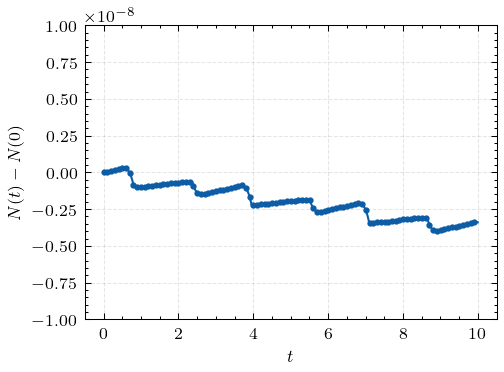

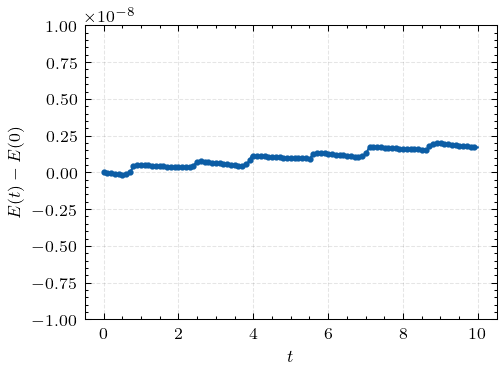

In [29]:
plt.figure()
plt.ylim(-1e-8, 1e-8)
mass_stand = w_stand.get_mass(plot=True, ms=2, markevery=10)#name=path+"energy_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3)))
#w_stand.get_mass(name=path+"energy_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3)), plot=True)

plt.figure()
plt.ylim(-1e-8, 1e-8)
energy_stand = w_stand.get_energy(plot=True, ms=2, markevery=10)#name=path+"mass_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3)))
#w_stand.get_energy(name=path+"mass_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3)), plot=True)

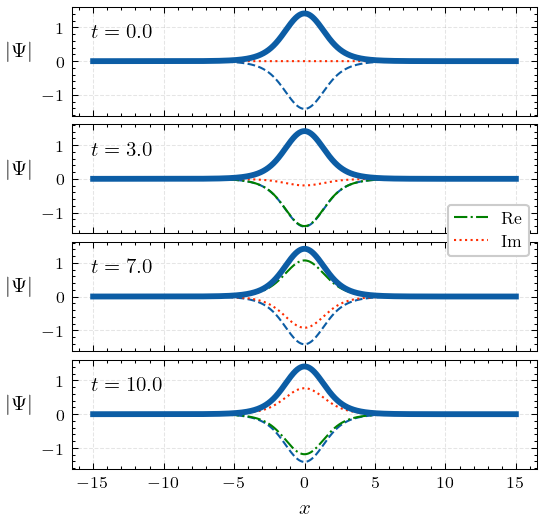

In [30]:
x = w_stand.x
t = w_stand.t
w_plot = w_stand.w
times_to_plot = [0, 3, 7, 10]

plot_snapshots(x, t, w_plot, times_to_plot, figsize=(4, 4), save_path="snapshots/standing_bright.pdf")#, L=15)

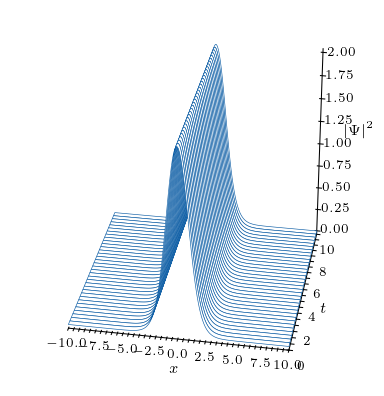

In [31]:
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"stand_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
#name_pgf = path+"stand_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_stand.w, w_stand.x, w_stand.t, name_pdf, labels, L=10)
#line_plot_3D(w_stand.w, w_stand.x, w_stand.t, name_pgf, labels, L=10)

In [32]:
ani = gif_snapshots(
    x,
    t,
    w_plot,
    save_path=path + "static_bright.gif",
    n_frames=80,
    fps=15,
    L=15,
)

## Moving

In [33]:
path = "Moving/"

L_theo = 20
N_theo = 20_001

k = 1/4

pars = {"k":k}
c = np.sqrt(2)
w = 1 #np.sqrt(2)/2

w_moving_theo, x_moving = soliton(c, k, w=w, soliton_type="bright", L=L_theo, N=N_theo, as_func=True)

Creating soliton...
Soliton created


In [34]:
x_0 = -5

def moving_soliton(x, t, c=c, w=w, x_0=x_0):
    i = 1j
    output = w_moving_theo(x-c*t-x_0) * np.exp(i*(-c**2/4*t-w*t))
    return output

In [35]:
L = 15
N = 10_000

tf = 10
Nt = 1000 

w_moving = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_moving.set_w_theo(moving_soliton)
w_moving.solve()#method="fixed point")

Iteration  1  of  1000 . Error:  5.8422077080949735e-12 . Newton iterations:  5
Iteration  2  of  1000 . Error:  5.893900499191071e-12 . Newton iterations:  5
Iteration  3  of  1000 . Error:  6.013421415977092e-12 . Newton iterations:  5
Iteration  4  of  1000 . Error:  6.199925461358295e-12 . Newton iterations:  5
Iteration  5  of  1000 . Error:  6.4569913460034336e-12 . Newton iterations:  5
Iteration  6  of  1000 . Error:  6.752230330260718e-12 . Newton iterations:  5
Iteration  7  of  1000 . Error:  7.102225629495614e-12 . Newton iterations:  5
Iteration  8  of  1000 . Error:  7.50971271028309e-12 . Newton iterations:  5
Iteration  9  of  1000 . Error:  7.952338231072873e-12 . Newton iterations:  5
Iteration  10  of  1000 . Error:  8.453797069894854e-12 . Newton iterations:  5
Iteration  11  of  1000 . Error:  8.9928116992966e-12 . Newton iterations:  5
Iteration  12  of  1000 . Error:  9.579307800118793e-12 . Newton iterations:  5
Iteration  13  of  1000 . Error:  1.02106451480350

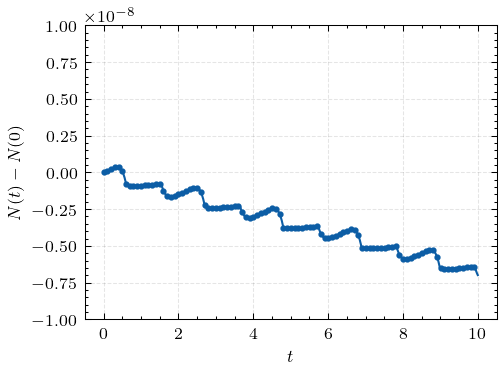

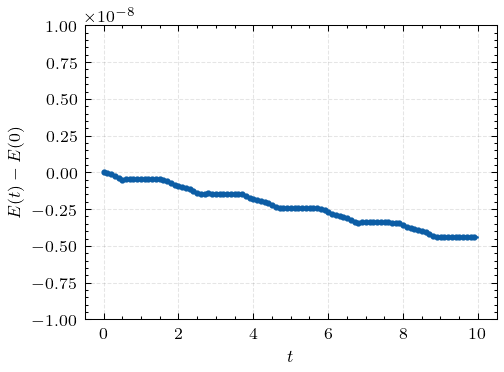

In [36]:
plt.figure()
plt.ylim(-1e-8, 1e-8)
mass_moving = w_moving.get_mass(plot=True, ms=2, markevery=10)#name=path+"mass_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
#mass_moving = w_moving.get_mass(name=path+"mass_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3)), plot=True)

plt.figure()
plt.ylim(-1e-8, 1e-8)
energy_moving = w_moving.get_energy(plot=True, ms=2, markevery=10)#name=path+"energy_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3)))
#energy_moving = w_moving.get_energy(name=path+"energy_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3)), plot=True)

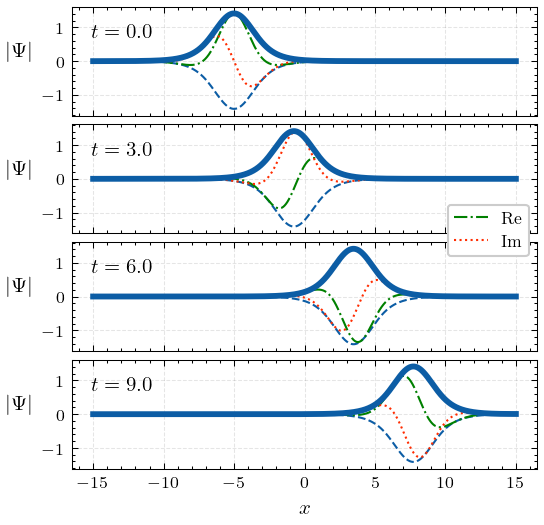

In [37]:
x = w_moving.x
t = w_moving.t
w_plot = w_moving.w
times_to_plot = [0, 3, 6, 9]

plot_snapshots(x, t, w_plot, times_to_plot, figsize=(4, 4), save_path="snapshots/moving_bright.pdf")#, L=15)

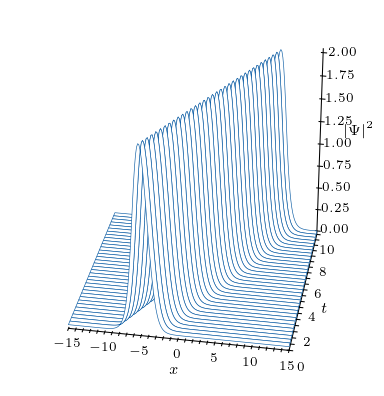

In [38]:
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"moving_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
#name_pgf = path+"moving_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_moving.w, w_moving.x, w_moving.t, name_pdf, labels, Nt_plot=35)
#line_plot_3D(w_moving.w, w_moving.x, w_moving.t, name_pgf, labels, Nt_plot=35)

In [39]:
ani = gif_snapshots(
    x,
    t,
    w_moving.w,
    save_path=path + "moving_bright.gif",
    n_frames=80,
    fps=15,
    L=15,
)

In [52]:
ani = animate_solution_with_invariants(
    w_moving,
    save_path=path + "moving_bright_with_invariants.gif",
    N_frames=10,
    fps=15,
    mass=mass_moving,
    energy=energy_moving,
    theo=True,
)

# Colissions

## $\kappa = 0$

In [2]:
L = 200
N = 40_000 #15_001
k = 0 #1/4

pars = {"k":k}
c_1 = np.sqrt(2)/2
c_2 = -np.sqrt(2)/2
w = 1/2 #np.sqrt(2)/2

w_col_stat_k_0, x_bright = soliton(0, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [3]:
x_0 = 15
def init_collision_k_0(x, t=0):
    i = 1j
    left_soliton = w_col_stat_k_0(x-c_1*t+x_0) * np.exp(-i*(c_1**2/4*t+c_1/2*x+w*t))
    right_soliton = w_col_stat_k_0(x-c_2*t-x_0) * np.exp(-i*(c_2**2/4*t+c_2/2*x+w*t))

    output = left_soliton + right_soliton
    return output

In [4]:
tf = 50
Nt = 1000

L_col = 80
N_col = 20_000

w_col_k_0 = Foc.CNFD(L_col, N_col, Nt, tf, pars, "neumann", order=2)
w_col_k_0.set_init_condition(init_collision_k_0)
w_col_k_0.solve(b_tol=1e-5)#method="fixed point")

Iteration  1  of  1000 . Error:  7.859165099248164e-12 . Newton iterations:  8
Iteration  2  of  1000 . Error:  8.98875580897673e-12 . Newton iterations:  8
Iteration  3  of  1000 . Error:  1.0221552033860537e-11 . Newton iterations:  8
Iteration  4  of  1000 . Error:  1.1553104490516142e-11 . Newton iterations:  8
Iteration  5  of  1000 . Error:  1.297229103143195e-11 . Newton iterations:  8
Iteration  6  of  1000 . Error:  1.4475995210388406e-11 . Newton iterations:  8
Iteration  7  of  1000 . Error:  1.604630936767023e-11 . Newton iterations:  8
Iteration  8  of  1000 . Error:  1.766950209116409e-11 . Newton iterations:  8
Iteration  9  of  1000 . Error:  1.9328762706932096e-11 . Newton iterations:  8
Iteration  10  of  1000 . Error:  2.1003642187350138e-11 . Newton iterations:  8
Iteration  11  of  1000 . Error:  2.2666491639927015e-11 . Newton iterations:  8
Iteration  12  of  1000 . Error:  2.4296859899367358e-11 . Newton iterations:  8
Iteration  13  of  1000 . Error:  2.5866447

MovieWriter ffmpeg unavailable; using Pillow instead.


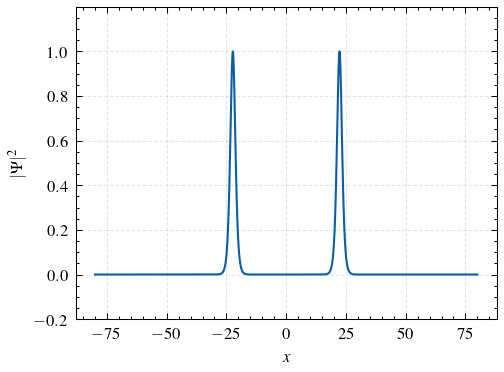

In [5]:
path = "Collisions_local/k_0/"
w_col_k_0.animate_solution(path+"colision.gif", 10)
#w_col_k_01.animate_solution(path+"colision_real.gif", 10, coord="real", auto_adjust=False)
#w_col_k_01.animate_solution(path+"colision_imag.gif", 10, coord="imag", auto_adjust=False)

## $\kappa = 0.1$

In [8]:
L = 200
N = 40_000 #15_001
k = 0.1 #1/4

pars = {"k":k}
c_1 = np.sqrt(2)/2
c_2 = -np.sqrt(2)/2
w = 1/2 #np.sqrt(2)/2

w_col_stat_k_01, x_bright = soliton(0, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [9]:
x_0 = 15
def init_collision_k_01(x, t=0):
    i = 1j
    left_soliton = w_col_stat_k_01(x-c_1*t+x_0) * np.exp(-i*(c_1**2/4*t+c_1/2*x+w*t))
    right_soliton = w_col_stat_k_01(x-c_2*t-x_0) * np.exp(-i*(c_2**2/4*t+c_2/2*x+w*t))

    output = left_soliton + right_soliton
    return output

In [10]:
tf = 50
Nt = 1000

L_col = 80
N_col = 20_000

w_col_k_01 = Foc.CNFD(L_col, N_col, Nt, tf, pars, "neumann", order=2)
w_col_k_01.set_init_condition(init_collision_k_01)
w_col_k_01.solve(b_tol=1e-5)#method="fixed point")

Iteration  1  of  1000 . Error:  1.3236736809903917e-10 . Newton iterations:  7
Iteration  2  of  1000 . Error:  1.4885190550528386e-10 . Newton iterations:  7
Iteration  3  of  1000 . Error:  1.6655438465290504e-10 . Newton iterations:  7
Iteration  4  of  1000 . Error:  1.8541011983424583e-10 . Newton iterations:  7
Iteration  5  of  1000 . Error:  2.0532040702649592e-10 . Newton iterations:  7
Iteration  6  of  1000 . Error:  2.2615299260554076e-10 . Newton iterations:  7
Iteration  7  of  1000 . Error:  2.4774193712561424e-10 . Newton iterations:  7
Iteration  8  of  1000 . Error:  2.6988568448427816e-10 . Newton iterations:  7
Iteration  9  of  1000 . Error:  2.923535819314208e-10 . Newton iterations:  7
Iteration  10  of  1000 . Error:  3.148859198070704e-10 . Newton iterations:  7
Iteration  11  of  1000 . Error:  3.371975699342363e-10 . Newton iterations:  7
Iteration  12  of  1000 . Error:  2.5931593330799482e-11 . Newton iterations:  8
Iteration  13  of  1000 . Error:  2.7649

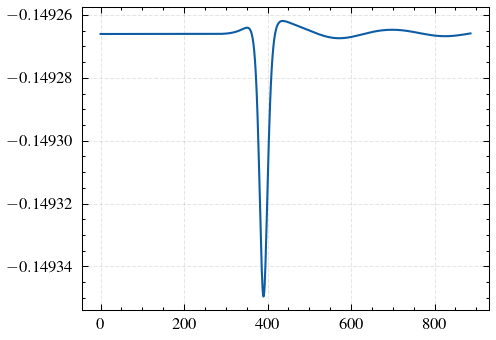

In [11]:
energy_col_k_01 = w_col_k_01.get_energy()
plt.plot(energy_col_k_01[energy_col_k_01!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


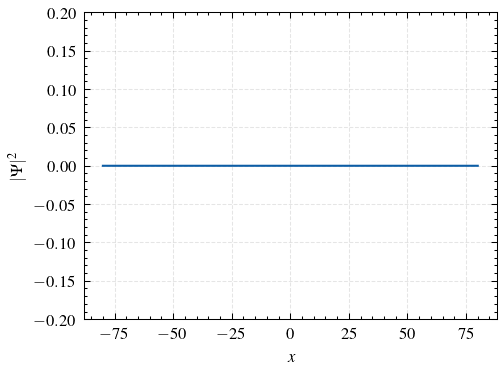

In [12]:
path = "Collisions_local/k_01/"
w_col_k_01.animate_solution(path+"colision.gif", 10)
#w_col_k_01.animate_solution(path+"colision_real.gif", 10, coord="real", auto_adjust=False)
#w_col_k_01.animate_solution(path+"colision_imag.gif", 10, coord="imag", auto_adjust=False)

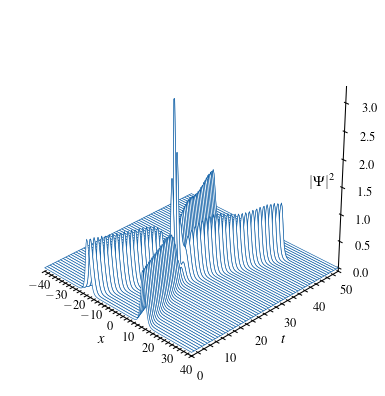

In [13]:
k = 0.1
path = "Collisions_local/k_01/"
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
#name_pgf = path+"collision_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_col_k_01.w, w_col_k_01.x, w_col_k_01.t, name_pdf, labels, L=40, Nt_plot=60, x_rot=-45, z_pad=-27)
#line_plot_3D(w_col_k_01.w, w_col_k_01.x, w_col_k_01.t, name_pgf, labels, L=25, tf=50, Nt_plot=60, x_rot=-45, z_pad=-27)

## $\kappa =  1$

In [44]:
L = 200
N = 40_000 #15_001
k = 1 #1/4

pars = {"k":k}
c_1 = np.sqrt(2)/2
c_2 = -np.sqrt(2)/2
w = 1/2 #np.sqrt(2)/2

w_col_stat_k_1, x_bright = soliton(0, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [45]:
x_0 = 15
def init_collision_k_1(x, t=0):
    i = 1j
    left_soliton = w_col_stat_k_1(x-c_1*t+x_0) * np.exp(-i*(c_1**2/4*t+c_1/2*x+w*t))
    right_soliton = w_col_stat_k_1(x-c_2*t-x_0) * np.exp(-i*(c_2**2/4*t+c_2/2*x+w*t))

    output = left_soliton + right_soliton
    return output

In [46]:
tf = 80
Nt = 3000

L_col = 150
N_col = 20_000

w_col_k_1 = Foc.CNFD(L_col, N_col, Nt, tf, pars, "neumann", order=2)
w_col_k_1.set_init_condition(init_collision_k_1)
w_col_k_1.solve(b_tol=1e-5)

Iteration  1  of  3000 . Error:  4.171776327223441e-14 . Newton iterations:  9
Iteration  2  of  3000 . Error:  4.4872129586320076e-14 . Newton iterations:  9
Iteration  3  of  3000 . Error:  4.7508526882475456e-14 . Newton iterations:  9
Iteration  4  of  3000 . Error:  5.0265620603256963e-14 . Newton iterations:  9
Iteration  5  of  3000 . Error:  5.358095090421704e-14 . Newton iterations:  9
Iteration  6  of  3000 . Error:  5.669918856828278e-14 . Newton iterations:  9
Iteration  7  of  3000 . Error:  6.007491631327203e-14 . Newton iterations:  9
Iteration  8  of  3000 . Error:  6.300182290062072e-14 . Newton iterations:  9
Iteration  9  of  3000 . Error:  6.635669477303206e-14 . Newton iterations:  9
Iteration  10  of  3000 . Error:  6.967085637746948e-14 . Newton iterations:  9
Iteration  11  of  3000 . Error:  7.356052511124415e-14 . Newton iterations:  9
Iteration  12  of  3000 . Error:  7.70889909902553e-14 . Newton iterations:  9
Iteration  13  of  3000 . Error:  8.07042973356

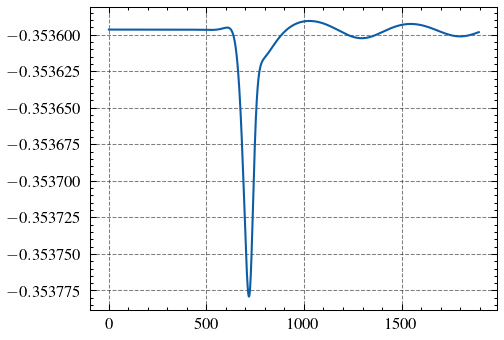

In [47]:
energy_col_k_1 = w_col_k_1.get_energy()
plt.plot(energy_col_k_1[energy_col_k_1!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


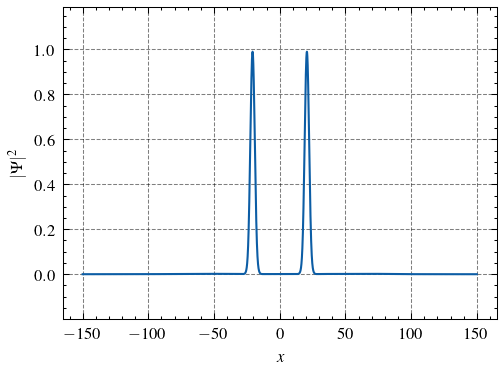

MovieWriter ffmpeg unavailable; using Pillow instead.


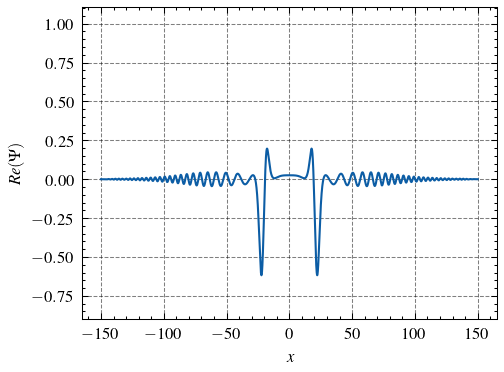

MovieWriter ffmpeg unavailable; using Pillow instead.


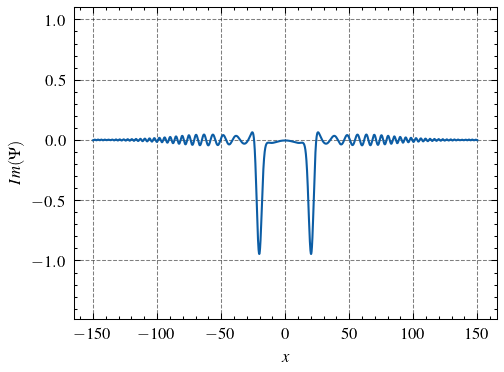

In [48]:
path = "Collisions_local/k_1/"
w_col_k_1.animate_solution(path+"colision.gif", 20)
w_col_k_1.animate_solution(path+"colision_real.gif", 20, coord="real", auto_adjust=False)
w_col_k_1.animate_solution(path+"colision_imag.gif", 20, coord="imag", auto_adjust=False)

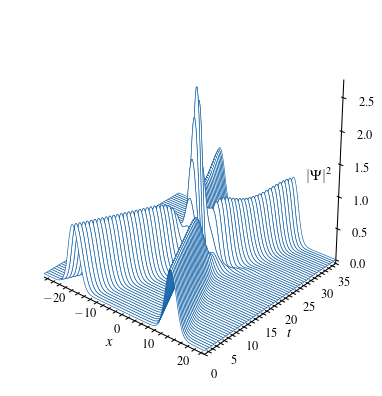

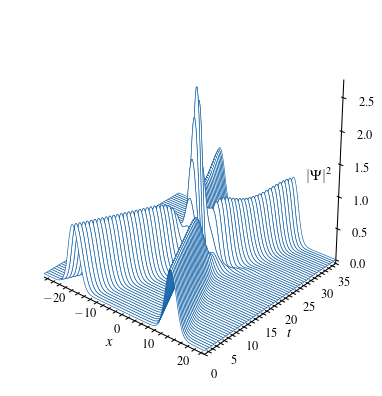

In [113]:
k = 1
path = "Collisions_local/k_1/"
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
name_pgf = path+"collision_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_col_k_1.w, w_col_k_1.x, w_col_k_1.t, name_pdf, labels, L=25, tf=35, Nt_plot=60, x_rot=-50, z_pad=-27)
line_plot_3D(w_col_k_1.w, w_col_k_1.x, w_col_k_1.t, name_pgf, labels, L=25, tf=35, Nt_plot=60, x_rot=-50, z_pad=-27)

## $\kappa =2.5$

In [51]:
L = 200
N = 40_000 #15_001
k = 2.5 #1/4

pars = {"k":k}
c_1 = np.sqrt(2)/2
c_2 = -np.sqrt(2)/2
w = 1/2 #np.sqrt(2)/2

w_col_stat_k_2_5, x_bright = soliton(0, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [53]:
x_0 = 15
def init_collision_k_2_5(x, t=0):
    i = 1j
    left_soliton = w_col_stat_k_2_5(x-c_1*t+x_0) * np.exp(-i*(c_1**2/4*t+c_1/2*x+w*t))
    right_soliton = w_col_stat_k_2_5(x-c_2*t-x_0) * np.exp(-i*(c_2**2/4*t+c_2/2*x+w*t))

    output = left_soliton + right_soliton
    return output

In [54]:
tf = 80
Nt = 3000

L_col = 150
N_col = 20_000

w_col_k_2_5 = Foc.CNFD(L_col, N_col, Nt, tf, pars, "neumann", order=2)
w_col_k_2_5.set_init_condition(init_collision_k_2_5)
w_col_k_2_5.solve(b_tol=1e-5)#method="fixed point")

Iteration  1  of  3000 . Error:  6.373092877669449e-14 . Newton iterations:  9
Iteration  2  of  3000 . Error:  6.64552543870127e-14 . Newton iterations:  9
Iteration  3  of  3000 . Error:  7.103688329672303e-14 . Newton iterations:  9
Iteration  4  of  3000 . Error:  7.325920443433208e-14 . Newton iterations:  9
Iteration  5  of  3000 . Error:  7.66179924769915e-14 . Newton iterations:  9
Iteration  6  of  3000 . Error:  8.166335243398533e-14 . Newton iterations:  9
Iteration  7  of  3000 . Error:  8.570744222753956e-14 . Newton iterations:  9
Iteration  8  of  3000 . Error:  8.980635736296253e-14 . Newton iterations:  9
Iteration  9  of  3000 . Error:  9.39099762129687e-14 . Newton iterations:  9
Iteration  10  of  3000 . Error:  9.777381844967492e-14 . Newton iterations:  9
Iteration  11  of  3000 . Error:  1.0323552523964867e-13 . Newton iterations:  9
Iteration  12  of  3000 . Error:  1.0588129863093933e-13 . Newton iterations:  9
Iteration  13  of  3000 . Error:  1.11869128130955

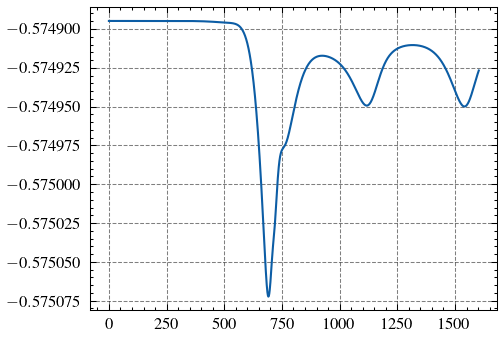

In [56]:
energy_col_k_2_5 = w_col_k_2_5.get_energy()
plt.plot(energy_col_k_2_5[energy_col_k_2_5!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


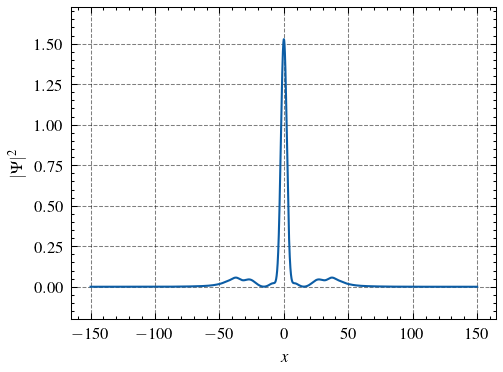

MovieWriter ffmpeg unavailable; using Pillow instead.


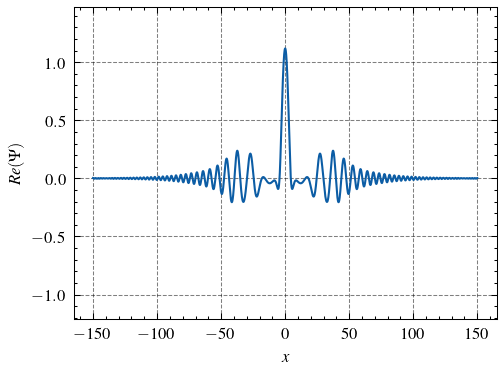

MovieWriter ffmpeg unavailable; using Pillow instead.


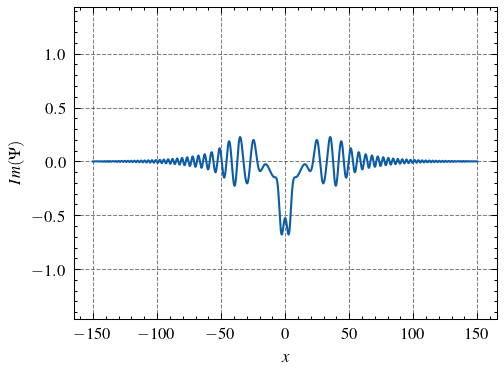

In [57]:
path = "Collisions_local/k_2.5/"
w_col_k_2_5.animate_solution(path+"colision.gif", 40)
w_col_k_2_5.animate_solution(path+"colision_real.gif", 40, coord="real", auto_adjust=False)
w_col_k_2_5.animate_solution(path+"colision_imag.gif", 40, coord="imag", auto_adjust=False)

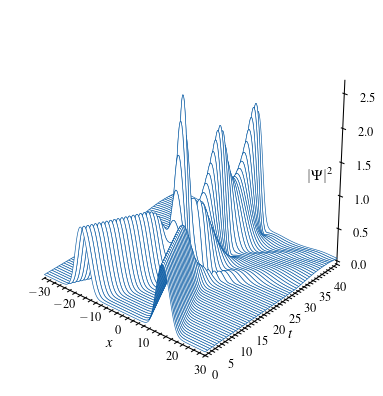

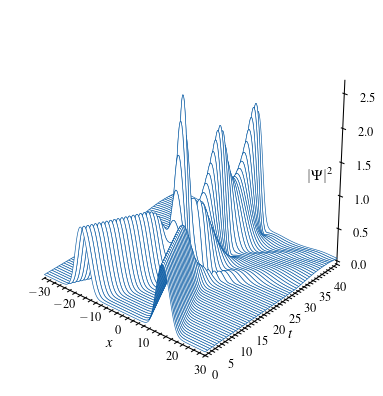

In [114]:
k = 2.5
path = "Collisions_local/k_2.5/"
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
name_pgf = path+"collision_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_col_k_2_5.w, w_col_k_2_5.x, w_col_k_2_5.t, name_pdf, labels, L=30, tf=42, Nt_plot=60, x_rot=-50, z_pad=-27)
line_plot_3D(w_col_k_2_5.w, w_col_k_2_5.x, w_col_k_2_5.t, name_pgf, labels, L=30, tf=42, Nt_plot=60, x_rot=-50, z_pad=-27)

## $\kappa =5$

In [62]:
L = 200
N = 40_000 #15_001
k = 5 #1/4

pars = {"k":k}
c_1 = np.sqrt(2)/2
c_2 = -np.sqrt(2)/2
w = 1/2 #np.sqrt(2)/2

w_col_stat_k_5, x_bright = soliton(0, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [63]:
x_0 = 15
def init_collision_k_5(x, t=0):
    i = 1j
    left_soliton = w_col_stat_k_5(x-c_1*t+x_0) * np.exp(-i*(c_1**2/4*t+c_1/2*x+w*t))
    right_soliton = w_col_stat_k_5(x-c_2*t-x_0) * np.exp(-i*(c_2**2/4*t+c_2/2*x+w*t))

    output = left_soliton + right_soliton
    return output

In [64]:
tf = 80
Nt = 3000

L_col = 150
N_col = 20_000

w_col_k_5 = Foc.CNFD(L_col, N_col, Nt, tf, pars, "neumann", order=2)
w_col_k_5.set_init_condition(init_collision_k_5)
w_col_k_5.solve(b_tol=1e-5)#method="fixed point")

Iteration  1  of  3000 . Error:  1.122114809687377e-13 . Newton iterations:  9
Iteration  2  of  3000 . Error:  1.167018056481536e-13 . Newton iterations:  9
Iteration  3  of  3000 . Error:  1.2221421340684516e-13 . Newton iterations:  9
Iteration  4  of  3000 . Error:  1.2704676063122704e-13 . Newton iterations:  9
Iteration  5  of  3000 . Error:  1.3258750282518567e-13 . Newton iterations:  9
Iteration  6  of  3000 . Error:  1.3773463502825886e-13 . Newton iterations:  9
Iteration  7  of  3000 . Error:  1.434319345503318e-13 . Newton iterations:  9
Iteration  8  of  3000 . Error:  1.4776356358262976e-13 . Newton iterations:  9
Iteration  9  of  3000 . Error:  1.54486331750728e-13 . Newton iterations:  9
Iteration  10  of  3000 . Error:  1.602182161989581e-13 . Newton iterations:  9
Iteration  11  of  3000 . Error:  1.6612325802224813e-13 . Newton iterations:  9
Iteration  12  of  3000 . Error:  1.7043088848800345e-13 . Newton iterations:  9
Iteration  13  of  3000 . Error:  1.7738822

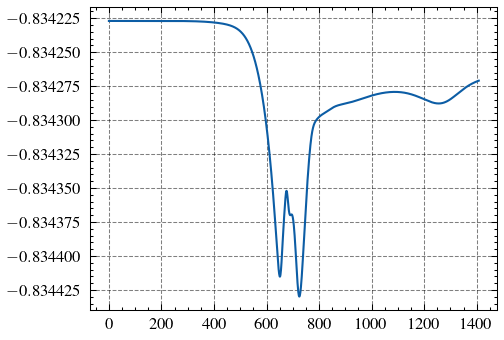

In [65]:
energy_col_k_5 = w_col_k_5.get_energy()
plt.plot(energy_col_k_5[energy_col_k_5!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


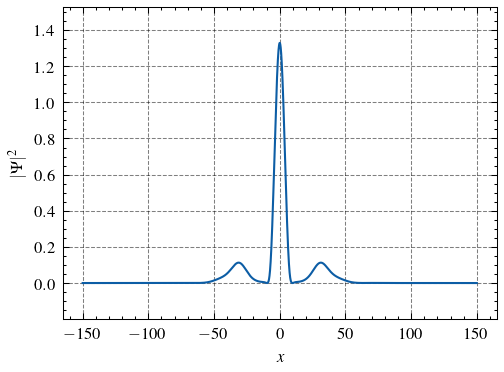

MovieWriter ffmpeg unavailable; using Pillow instead.


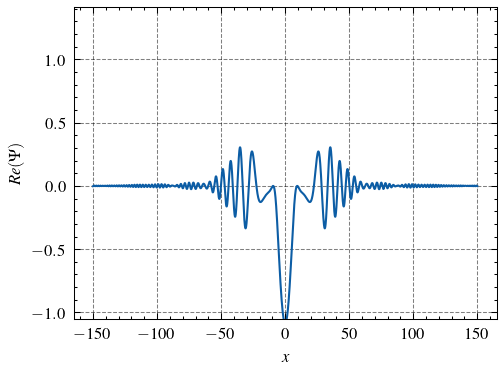

MovieWriter ffmpeg unavailable; using Pillow instead.


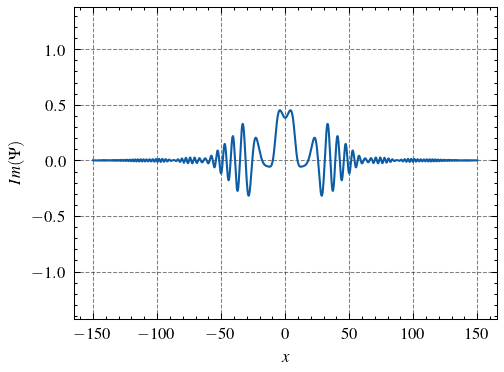

In [66]:
path = "Collisions_local/k_5/"
w_col_k_5.animate_solution(path+"colision.gif", 40)
w_col_k_5.animate_solution(path+"colision_real.gif", 40, coord="real", auto_adjust=False)
w_col_k_5.animate_solution(path+"colision_imag.gif", 40, coord="imag", auto_adjust=False)

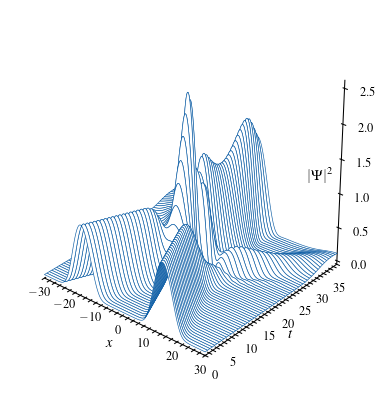

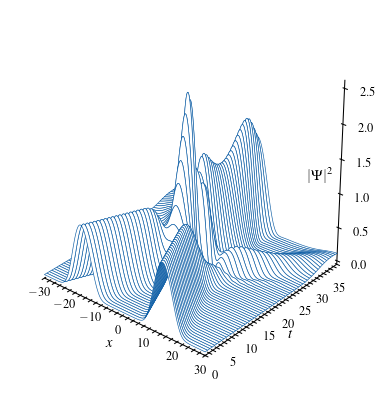

In [123]:
k = 5
path = "Collisions_local/k_5/"
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
name_pgf = path+"collision_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_col_k_5.w, w_col_k_5.x, w_col_k_5.t, name_pdf, labels, L=30, tf=37, Nt_plot=60, x_rot=-50, z_pad=-27)
line_plot_3D(w_col_k_5.w, w_col_k_5.x, w_col_k_5.t, name_pgf, labels, L=30, tf=37, Nt_plot=60, x_rot=-50, z_pad=-27)

## $\kappa = 10$

In [70]:
L = 200
N = 40_000 #15_001
k = 10 #1/4

pars = {"k":k}
c_1 = np.sqrt(2)/2
c_2 = -np.sqrt(2)/2
w = 1/2 #np.sqrt(2)/2

w_col_stat_k_10, x_bright = soliton(0, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [71]:
x_0 = 15
def init_collision_k_10(x, t=0):
    i = 1j
    left_soliton = w_col_stat_k_10(x-c_1*t+x_0) * np.exp(-i*(c_1**2/4*t+c_1/2*x+w*t))
    right_soliton = w_col_stat_k_10(x-c_2*t-x_0) * np.exp(-i*(c_2**2/4*t+c_2/2*x+w*t))

    output = left_soliton + right_soliton
    return output

In [73]:
tf = 80
Nt = 3000

L_col = 150
N_col = 20_000

w_col_k_10 = Foc.CNFD(L_col, N_col, Nt, tf, pars, "neumann", order=2)
w_col_k_10.set_init_condition(init_collision_k_10)
w_col_k_10.solve(b_tol=1e-5)#method="fixed point")

Iteration  1  of  3000 . Error:  4.3375158531371005e-13 . Newton iterations:  9
Iteration  2  of  3000 . Error:  4.48792562963807e-13 . Newton iterations:  9
Iteration  3  of  3000 . Error:  4.632119790246956e-13 . Newton iterations:  9
Iteration  4  of  3000 . Error:  4.783986579457013e-13 . Newton iterations:  9
Iteration  5  of  3000 . Error:  4.932367075870705e-13 . Newton iterations:  9
Iteration  6  of  3000 . Error:  5.101310429775474e-13 . Newton iterations:  9
Iteration  7  of  3000 . Error:  5.238652118104191e-13 . Newton iterations:  9
Iteration  8  of  3000 . Error:  5.395608625801673e-13 . Newton iterations:  9
Iteration  9  of  3000 . Error:  5.550645541526612e-13 . Newton iterations:  9
Iteration  10  of  3000 . Error:  5.710394349478157e-13 . Newton iterations:  9
Iteration  11  of  3000 . Error:  5.852518562780214e-13 . Newton iterations:  9
Iteration  12  of  3000 . Error:  6.010561954492579e-13 . Newton iterations:  9
Iteration  13  of  3000 . Error:  6.1560382108118

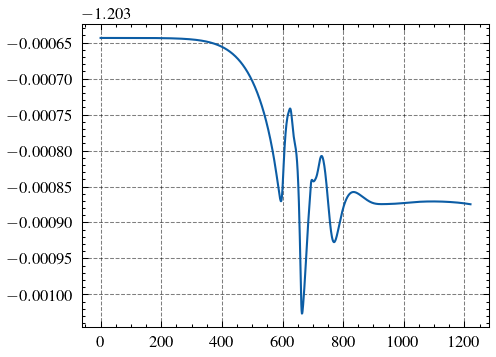

In [74]:
energy_col_k_10 = w_col_k_10.get_energy()
plt.plot(energy_col_k_10[energy_col_k_10!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


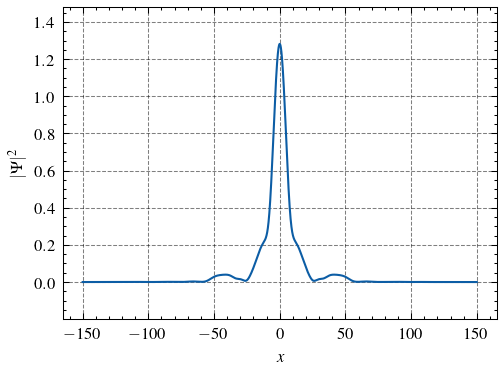

MovieWriter ffmpeg unavailable; using Pillow instead.


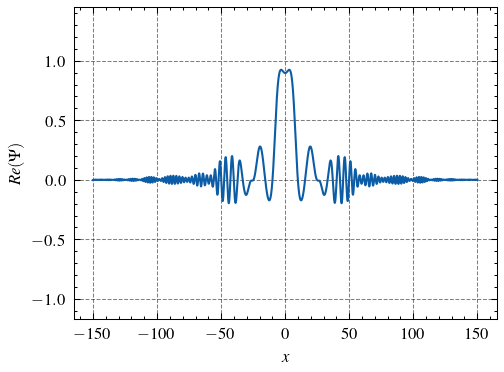

MovieWriter ffmpeg unavailable; using Pillow instead.


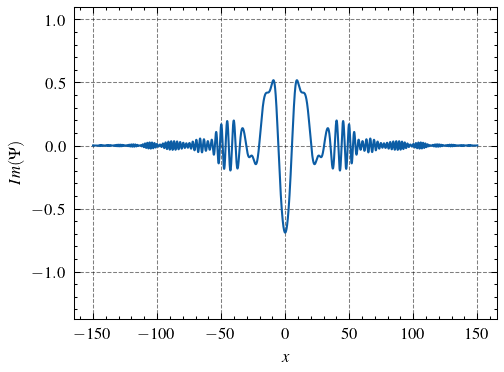

In [75]:
path = "Collisions_local/k_10/"
w_col_k_10.animate_solution(path+"colision.gif", 40)
w_col_k_10.animate_solution(path+"colision_real.gif", 40, coord="real", auto_adjust=False)
w_col_k_10.animate_solution(path+"colision_imag.gif", 40, coord="imag", auto_adjust=False)

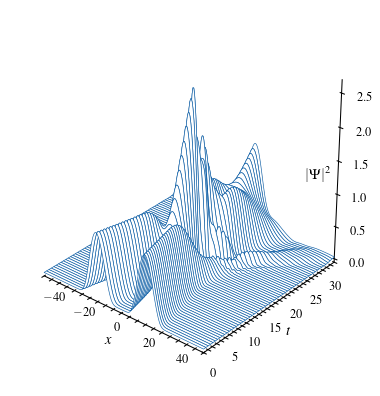

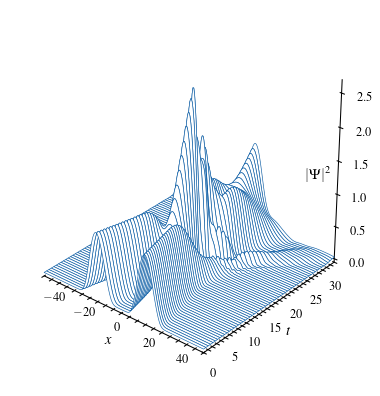

In [116]:
k = 10
path = "Collisions_local/k_10/"
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))
name_pgf = path+"collision_k_{k}_w_{w}_c_{c}.pgf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(w_col_k_10.w, w_col_k_10.x, w_col_k_10.t, name_pdf, labels, L=50, tf=32, Nt_plot=60, x_rot=-50, z_pad=-27)
line_plot_3D(w_col_k_10.w, w_col_k_10.x, w_col_k_10.t, name_pgf, labels, L=50, tf=32, Nt_plot=60, x_rot=-50, z_pad=-27)

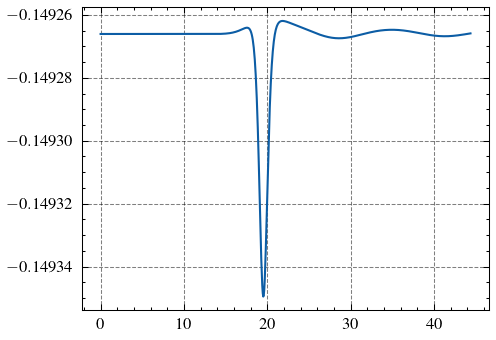

In [81]:
plt.plot(w_col_k_01.t[energy_col_k_01!=0], energy_col_k_01[energy_col_k_01!=0])
#plt.plot(w_col_k_1.t[energy_col_k_1!=0], energy_col_k_1[energy_col_k_1!=0])
#plt.plot(w_col_k_2_5.t[energy_col_k_2_5!=0], energy_col_k_2_5[energy_col_k_2_5!=0])
#plt.plot(w_col_k_5.t[energy_col_k_5!=0], energy_col_k_5[energy_col_k_5!=0])
#plt.plot(w_col_k_10.t[energy_col_k_10!=0], energy_col_k_10[energy_col_k_10!=0])
plt.show()

# Collisions files

In [3]:
ks = [0, 0.01, 0.1, 1, 1.5]
path_base = "../../../Heaven_scripts/Results/Bright/"

energies_L = []
energies_R = []
energies = []
arg_maxes_L = []
arg_maxes_R = []
arg_maxes = []
times = []
masses_L = []
masses_R = []
masses = []
norms_inf = []

for k in ks:
    path = path_base+"bright_collision_N_500000_Nt_80000_L_400_w_0.5_k_{k}_c_0.71/".format(k=k)

    energy_L_file = gzip.GzipFile(path+"energy_L.npy.gz", "r")
    energy_L = np.load(energy_L_file)
    energies_L += [energy_L]

    energy_R_file = gzip.GzipFile(path+"energy_R.npy.gz", "r")
    energy_R = np.load(energy_R_file)
    energies_R += [energy_R]

    energy_file = gzip.GzipFile(path+"energy.npy.gz", "r")
    energy = np.load(energy_file)
    energies += [energy]

    arg_max_L_file = gzip.GzipFile(path+"arg_max_L.npy.gz", "r")
    arg_max_L = np.load(arg_max_L_file)
    arg_maxes_L += [arg_max_L]

    arg_max_R_file = gzip.GzipFile(path+"arg_max_R.npy.gz", "r")
    arg_max_R = np.load(arg_max_R_file)
    arg_maxes_R += [arg_max_R]
    
    arg_max_file = gzip.GzipFile(path+"arg_max.npy.gz", "r")
    arg_max = np.load(arg_max_file)
    arg_maxes += [arg_max]
    
    time_file = gzip.GzipFile(path+"time.npy.gz", "r")
    t = np.load(time_file)
    times += [t]

    mass_L_file = gzip.GzipFile(path+"mass_L.npy.gz", "r")
    mass_L = np.load(mass_L_file)
    masses_L += [mass_L]

    mass_R_file = gzip.GzipFile(path+"mass_R.npy.gz", "r")
    mass_R = np.load(mass_R_file)
    masses_R += [mass_R]

    mass_file = gzip.GzipFile(path+"mass.npy.gz", "r")
    mass = np.load(mass_file)
    masses += [mass]

    norm_inf_file = gzip.GzipFile(path+"norm_inf.npy.gz", "r")
    norm_inf = np.load(norm_inf_file)
    norms_inf += [norm_inf]

## Evolution

In [6]:
x_0 = 20
Nt = 80_000
N = 500_000
L = 400
Nelem = 100
N_times = int(Nt/Nelem)
sols = []
t_plot = []

for j in range(len(ks)):
    k = ks[j]

    sols_ = np.full(Nelem, fill_value=None)
    path = path_base+"bright_collision_N_500000_Nt_80000_L_400_w_0.5_k_{k}_c_0.71/".format(k=k)
    
    for n in range(Nelem):
        m = n * N_times
        sol_file = gzip.GzipFile(path + "w_"+f"{m:010d}"+".npy.gz", "r")
        sol = np.load(sol_file)
        sols_[n] = sol

    sols_ = np.stack(sols_)
    sols += [sols_]

for n in range(Nelem):
    m = n * N_times
    t_plot += [t[m]]

t_plot = np.array(t_plot)
#sols = np.array(sols)
#sols = np.stack(sols)

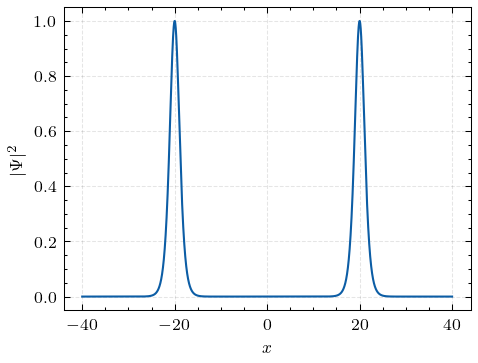

In [57]:
path_save = "Collisions_machine/"
x = np.linspace(-L, L, N)
cond = np.abs(x)<40
plt.plot(x[cond], norm(sols[0][0][cond]), ls="-", marker="none")
plt.xlabel(r"$x$")
plt.ylabel(r"$|\Psi|^2$")
#plt.savefig(path_save+"init_cond_example.pdf", dpi=300, bbox_inches = "tight")
plt.show()

In [59]:
def animate_solution(sol, x, name, N_frames):
    # Create figure
    fig, ax = plt.subplots()

    line1, = ax.plot(x, norm(sol[0]), label="Simulation", ls="-", marker="none")
    
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$|\Psi|^2$", rotation=0, labelpad=15)

    max_val = norm(sol).max().max()
    min_val = norm(sol).min().min()
    ax.set_ylim(min_val-0.1, max_val+0.1)

    fig.set_tight_layout(True)

    # Animate function
    def animate(j):
        line1.set_data(x, norm(sol[j]))
        return line1,

    # Animación
    N_final = len(sol)
    ani = animation.FuncAnimation(fig, animate, frames=np.arange(0, N_final, N_frames), 
                                  interval=150)

    ani.save(name, bitrate=-1, codec="libx264")
    plt.show()

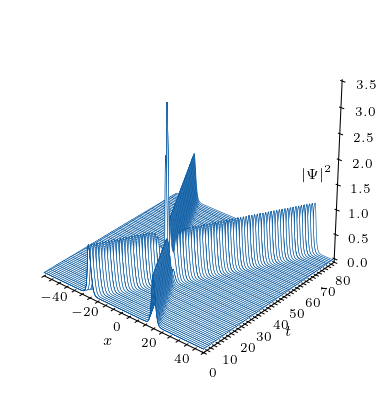

In [62]:
j = 0
k = ks[j]
w = 1/2
c = np.sqrt(2)/2
x = np.linspace(-L, L, N)

path_save = "Collisions_machine/k_{}/".format(k)

labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path_save+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(sols[j], x, t_plot, name_pdf, labels, L=50, tf=80, Nt_plot=100, N_plot=500, x_rot=-50, z_pad=-27)

MovieWriter ffmpeg unavailable; using Pillow instead.


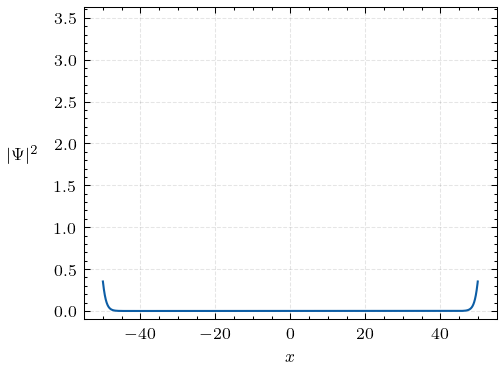

In [67]:
animate_solution(sols[j][:, np.abs(x)<50], x[np.abs(x)<50], path_save+"collision.gif", 2)

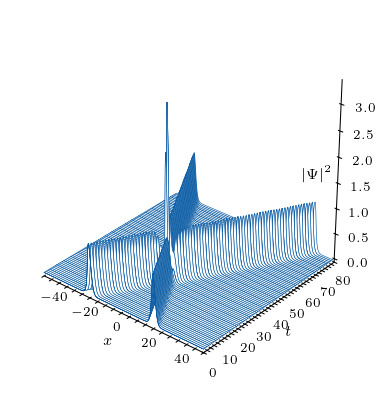

In [68]:
j = 1
k = ks[j]
w = 1/2
c = np.sqrt(2)/2
x = np.linspace(-L, L, N)

path_save = "Collisions_machine/k_{}/".format(k)

labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path_save+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(sols[j], x, t_plot, name_pdf, labels, L=50, tf=80, Nt_plot=100, N_plot=500, x_rot=-50, z_pad=-27)

MovieWriter ffmpeg unavailable; using Pillow instead.


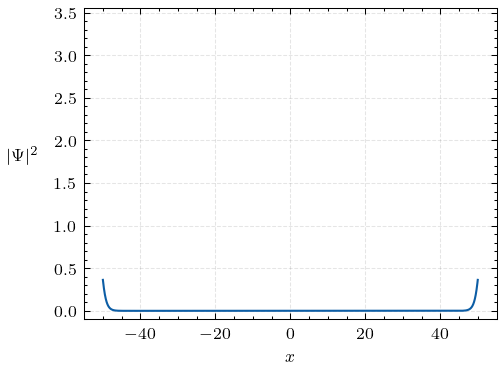

In [70]:
animate_solution(sols[j][:, np.abs(x)<50], x[np.abs(x)<50], path_save+"collision.gif", 2)

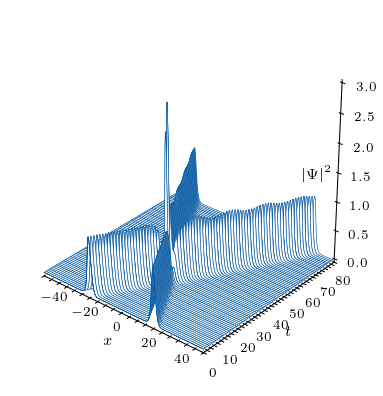

In [71]:
j = 2
k = ks[j]
w = 1/2
c = np.sqrt(2)/2
x = np.linspace(-L, L, N)

path_save = "Collisions_machine/k_{}/".format(k)

labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path_save+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(sols[j], x, t_plot, name_pdf, labels, L=50, tf=80, Nt_plot=100, N_plot=500, x_rot=-50, z_pad=-27)

MovieWriter ffmpeg unavailable; using Pillow instead.


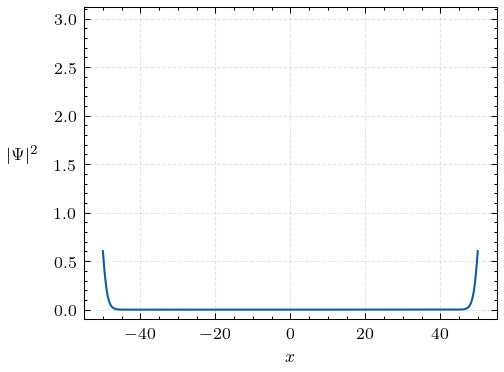

In [72]:
animate_solution(sols[j][:, np.abs(x)<50], x[np.abs(x)<50], path_save+"collision.gif", 2)

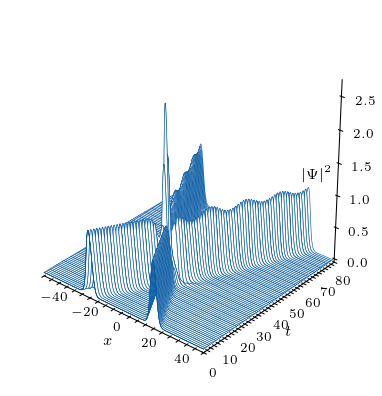

In [73]:
j = 3
k = ks[j]
w = 1/2
c = np.sqrt(2)/2
x = np.linspace(-L, L, N)

path_save = "Collisions_machine/k_{}/".format(k)

labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path_save+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(sols[j], x, t_plot, name_pdf, labels, L=50, tf=80, Nt_plot=100, N_plot=500, x_rot=-50, z_pad=-27)

MovieWriter ffmpeg unavailable; using Pillow instead.


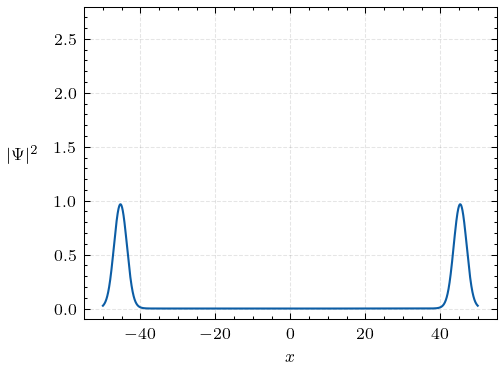

In [74]:
animate_solution(sols[j][:, np.abs(x)<50], x[np.abs(x)<50], path_save+"collision.gif", 2)

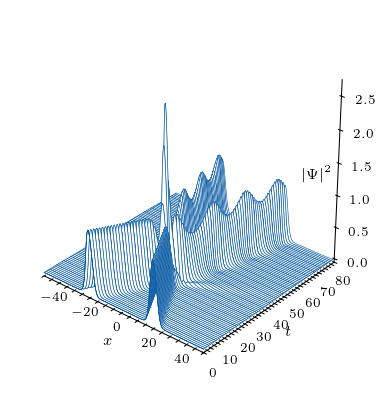

In [77]:
j = 4
k = ks[j]
w = 1/2
c = np.sqrt(2)/2
x = np.linspace(-L, L, N)

path_save = "Collisions_machine/k_{}/".format(k)

labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path_save+"collision_k_{k}_w_{w}_c_{c}.pdf".format(k=k, w=w, c=round(c, 3))

line_plot_3D(sols[j], x, t_plot, name_pdf, labels, L=50, tf=80, Nt_plot=100, N_plot=500, x_rot=-50, z_pad=-27)

MovieWriter ffmpeg unavailable; using Pillow instead.


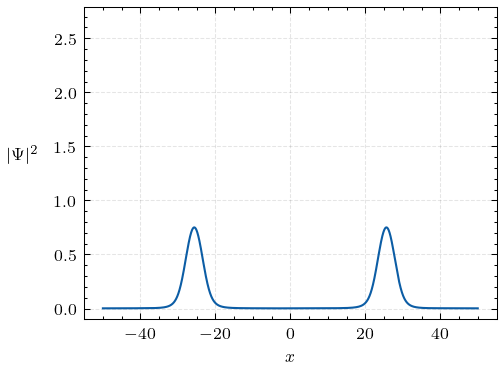

In [78]:
animate_solution(sols[j][:, np.abs(x)<50], x[np.abs(x)<50], path_save+"collision.gif", 2)

## Energy

In [7]:
dt = np.abs(t[1] - t[0])

dEs = []
dNs = []
for j in range(len(ks)):
    dE = np.gradient(energies_R[j], dt)
    dN = np.gradient(masses_R[j], dt)
    dEs += [dE]
    dNs += [dN]

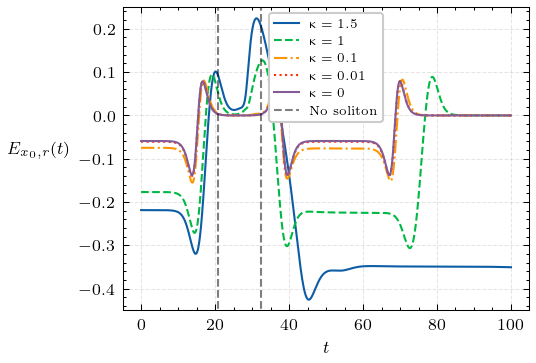

In [8]:
# Needs explanation
w_l = np.where(np.abs(masses_R[0])<1e-2)[0][1]
w_r = np.where(dNs[0]>1e-2)[0][0]

for j in range(len(ks)-1, -1, -1):
    plt.plot(times[j], energies_R[j], label=r"$\upkappa={}$".format(ks[j]), marker="none")#markevery=1500,
             #markerfacecolor="none")

#plt.vlines(times[-1][np.where(np.abs(dEs[-1])>1e-2)[0][0]], -1, 1, ls="--", label="Soliton leaving", color="black")

plt.vlines(times[0][w_l], -1, 6, ls="--", label="No soliton", color="black", alpha=0.5)
plt.vlines(times[0][w_r], -1, 6, ls="--", color="black", alpha=0.5)

#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")
plt.xlabel(r"$t$")
plt.ylabel(r"$E_{x_0, r}(t)$", rotation='horizontal', ha='right')

plt.ylim(-0.45, 0.25)
plt.legend(fontsize=6)

plt.savefig("Collisions_dispersion/local_energies_ks.pdf", dpi=300, bbox_inches = "tight")

plt.show()

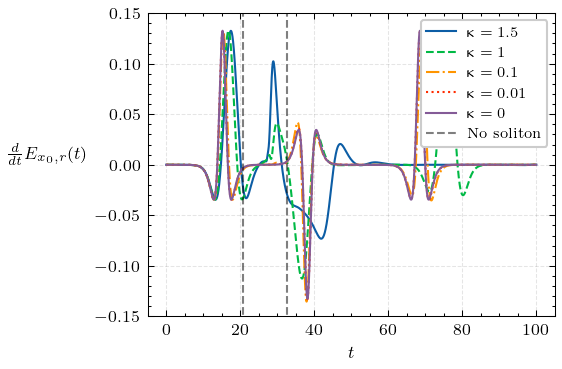

In [9]:
# Needs explanation

for j in range(len(ks)-1, -1, -1):
    dE = dEs[j]
    #cond = np.logical_and(24<times[j], times[j]<35)
    plt.plot(times[j], dE, label=r"$\upkappa={}$".format(ks[j]), marker="none")#markevery=1500,
             #markerfacecolor="none")
#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")

#plt.vlines(times[-1][np.where(np.abs(dEs[-1])>5e-3)[0][0]], -1, 1, ls="--", label="Soliton leaving", color="black")

plt.vlines(times[0][w_l], -1, 6, ls="--", label="No soliton", color="black", alpha=0.5)
plt.vlines(times[0][w_r], -1, 6, ls="--", color="black", alpha=0.5)

plt.xlabel(r"$t$")
plt.ylabel(r"$\frac{d}{dt}E_{x_0, r}(t)$", rotation='horizontal', ha='right')

plt.ylim(-0.15, 0.15)
plt.legend(fontsize=7)

plt.savefig("Collisions_dispersion/der_local_energies_ks.pdf", dpi=300, bbox_inches = "tight")

plt.show()

## Mass

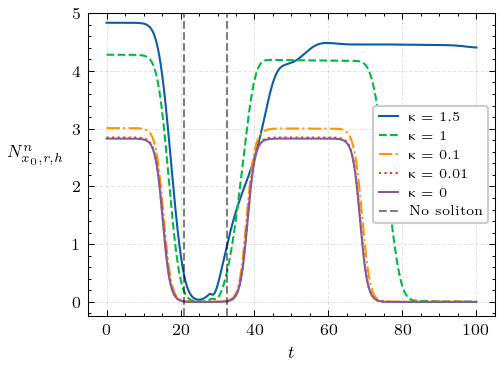

In [12]:
# Nice

for j in range(len(ks)-1, -1, -1):
    #j = 1
    cond = np.logical_and(24<times[j], times[j]<31)
    plt.plot(times[j], masses_R[j], label=r"$\upkappa={}$".format(ks[j]), marker="none")#, markevery=1500,
             #markerfacecolor="none") [cond]
#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")
plt.vlines(times[0][w_l], -1, 6, ls="--", label="No soliton", color="black", alpha=0.5)
plt.vlines(times[0][w_r], -1, 6, ls="--", color="black", alpha=0.5)

plt.xlabel(r"$t$")
plt.ylabel(r"$N_{x_0, r, h}^n$", rotation='horizontal', ha='right')
plt.ylim(-0.25, 5)
plt.legend(fontsize=6.5, loc="center right", handlelength=1.4)

plt.savefig("Collisions_dispersion/local_masses_ks.pdf", dpi=300, bbox_inches = "tight")

plt.show()

Window values:  20.841510518881485 32.509156364454554


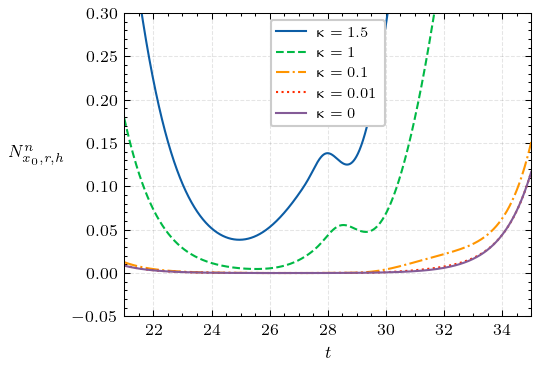

In [13]:
# Nice
for j in range(len(ks)-1, -1, -1):
    #j = 1
    #cond = np.logical_and(21<times[j], times[j]<35)
    plt.plot(times[j], masses_R[j], label=r"$\upkappa={}$".format(ks[j]), marker="none")#, markevery=1500,
             #markerfacecolor="none") [cond]
#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")

plt.xlabel(r"$t$")
plt.ylabel(r"$N_{x_0, r, h}^n$", rotation='horizontal', ha='right')
plt.legend(fontsize=7)

plt.xlim(21, 35)
plt.ylim(-0.05, 0.3)
plt.savefig("Collisions_dispersion/local_masses_ks_zoom.pdf", dpi=300, bbox_inches = "tight")

print("Window values: ", times[0][w_l], times[0][w_r])
plt.show()

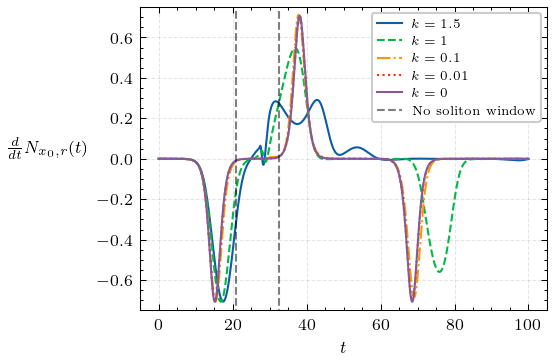

In [10]:
# Needs explanation
dt = np.abs(t[1] - t[0])

for j in range(len(ks)-1, -1, -1):
    #cond = np.logical_and(24<times[j], times[j]<35)
    dN = dNs[j]
    plt.plot(times[j], dN, label=r"$k={}$".format(ks[j]), marker="none")#markevery=1500,
             #markerfacecolor="none")
#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")

plt.vlines(times[0][w_l], -1, 1, ls="--", label="No soliton window", color="black", alpha=0.5)
plt.vlines(times[0][w_r], -1, 1, ls="--", color="black", alpha=0.5)

plt.xlabel(r"$t$")
plt.ylabel(r"$\frac{d}{dt}N_{x_0, r}(t)$", rotation='horizontal', ha='right')

plt.ylim(-0.75, 0.75)
plt.legend(fontsize=6)

plt.savefig("Collisions_dispersion/der_local_masses_ks.pdf", dpi=300, bbox_inches = "tight")
plt.show()

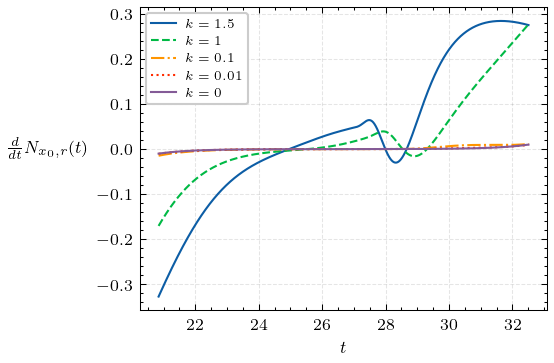

In [11]:
# Needs explanation
dt = np.abs(t[1] - t[0])

for j in range(len(ks)-1, -1, -1):
    cond = np.logical_and(times[0][w_l]<times[j], times[j]<times[0][w_r])
    plt.plot(times[j][cond], dNs[j][cond], label=r"$k={}$".format(ks[j]), marker="none")#markevery=1500,
             #markerfacecolor="none")
#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")
plt.xlabel(r"$t$")
plt.ylabel(r"$\frac{d}{dt}N_{x_0, r}(t)$", rotation='horizontal', ha='right')
plt.legend(fontsize=6)

plt.savefig("Collisions_dispersion/der_local_masses_ks_zoom.pdf", dpi=300, bbox_inches = "tight")

plt.show()

## Trajectories

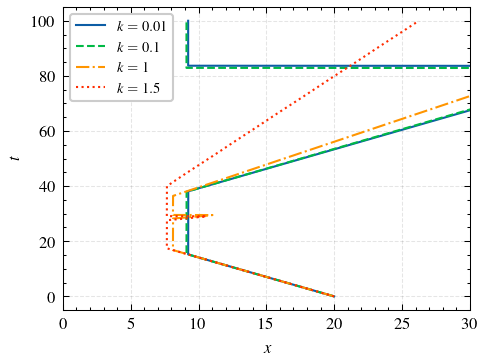

In [9]:
colors = ['#0C5DA5', '#00B945', '#FF9500', '#FF2C00']
lines = ['-', '--', '-.', ':']
for j in range(len(ks)):
    color = colors[j]
    line = lines[j]
    plt.plot(arg_maxes_R[j], times[j], color=color, label=r"$k={}$".format(ks[j]), markevery=1500,
             marker="none", ls=line, lw=1)
    plt.plot(arg_maxes_L[j], times[j], color=color, markevery=1500,
             marker="none", ls=line, lw=1)

#plt.plot(t[t<t_back], arg_max_R[t<t_back], label="right")
#plt.plot(t, energy_L[energy_L!=0], label="left")
#plt.plot(energy[energy!=0], label="total")
plt.xlim(0, 30)
plt.xlabel(r"$x$")
plt.ylabel(r"$t$")
plt.legend(fontsize=7)

#plt.savefig("Collisions_machine/Local_traj_ks.pdf", dpi=300, bbox_inches = "tight")

plt.show()

(-50.0, 50.0)

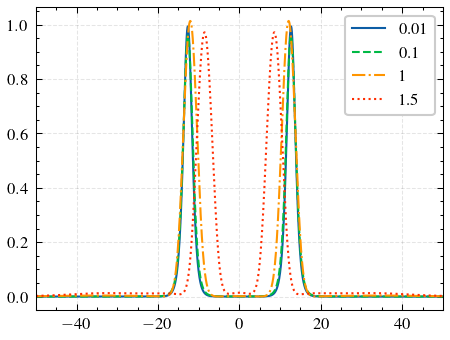

In [121]:
j = 43
x = np.linspace(-L, L, N)
#cond = np.abs(x-20)<10.887221774443503
plt.plot(x, norm(sols[0][j]), marker="none", label=ks[0])
plt.plot(x, norm(sols[1][j]), marker="none", label=ks[1])
plt.plot(x, norm(sols[2][j]), marker="none", label=ks[2])
plt.plot(x, norm(sols[3][j]), marker="none", label=ks[3])
plt.legend()
#plt.ylim(-0.01, 0.02)
plt.xlim(-50, 50)

(20.0, 40.0)

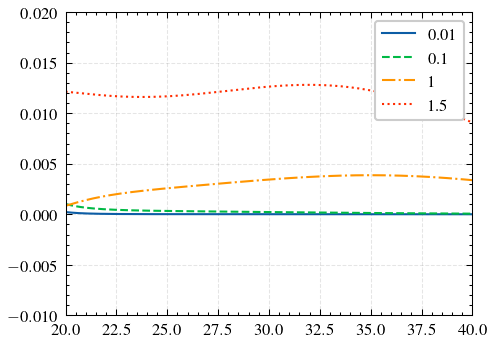

In [122]:
j = 43
x = np.linspace(-L, L, N)
#cond = np.abs(x-20)<10.887221774443503
plt.plot(x, norm(sols[0][j]), marker="none", label=ks[0])
plt.plot(x, norm(sols[1][j]), marker="none", label=ks[1])
plt.plot(x, norm(sols[2][j]), marker="none", label=ks[2])
plt.plot(x, norm(sols[3][j]), marker="none", label=ks[3])
plt.legend()
plt.ylim(-0.01, 0.02)
plt.xlim(20, 40)

# Wave dec

## $A = 1$

In [42]:
k = 0.1

pars = {"k":k}

def sech_init(x, A):
    i = 1j
    output = A * sech(x/np.sqrt(2))
    return output

In [43]:
tf = 20
Nt = 2000
L = 80
N = 40_000 #15_001
A_sech = 1
sech_init_A_1 = lambda x: sech_init(x, A_sech)

w_sech_A_1 = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sech_A_1.set_init_condition(sech_init_A_1)
w_sech_A_1.solve(b_tol=1e-5)

Iteration  1  of  2000 . Error:  3.44202683469207e-12 . Newton iterations:  4
Iteration  2  of  2000 . Error:  3.4455270504485234e-12 . Newton iterations:  4
Iteration  3  of  2000 . Error:  3.446270241159998e-12 . Newton iterations:  4
Iteration  4  of  2000 . Error:  3.4513303369768876e-12 . Newton iterations:  4
Iteration  5  of  2000 . Error:  3.4608227743998504e-12 . Newton iterations:  4
Iteration  6  of  2000 . Error:  3.4693402184312396e-12 . Newton iterations:  4
Iteration  7  of  2000 . Error:  3.484890670011254e-12 . Newton iterations:  4
Iteration  8  of  2000 . Error:  3.5006735999845852e-12 . Newton iterations:  4
Iteration  9  of  2000 . Error:  3.516689518920976e-12 . Newton iterations:  4
Iteration  10  of  2000 . Error:  3.5371383353717833e-12 . Newton iterations:  4
Iteration  11  of  2000 . Error:  3.556427574180802e-12 . Newton iterations:  4
Iteration  12  of  2000 . Error:  3.580539925860328e-12 . Newton iterations:  4
Iteration  13  of  2000 . Error:  3.60592041

KeyboardInterrupt: 

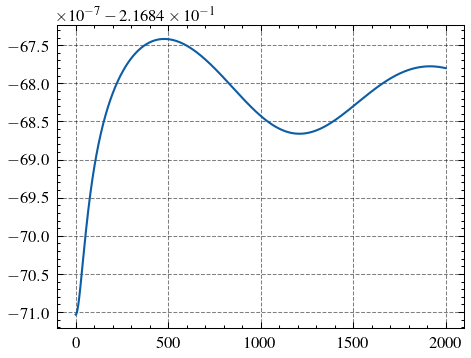

In [85]:
energy_sech_A_1 = w_sech_A_1.get_energy()
plt.plot(energy_sech_A_1[energy_sech_A_1!=0])

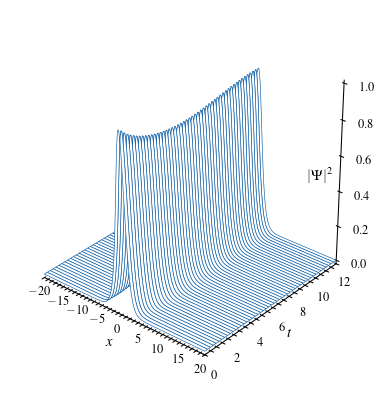

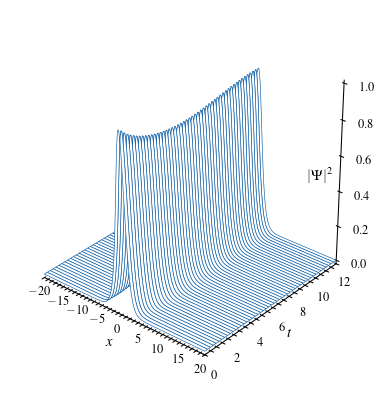

In [89]:
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"sech_init_A_{A}.pdf".format(A=A_sech)
name_pgf = path+"sech_init_A_{A}.pgf".format(A=A_sech)

line_plot_3D(w_sech_A_1.w, w_sech_A_1.x, w_sech_A_1.t, name_pdf, labels, L=20, tf=12, Nt_plot=50, x_rot=-50, z_pad=-27)
line_plot_3D(w_sech_A_1.w, w_sech_A_1.x, w_sech_A_1.t, name_pgf, labels, L=20, tf=12, Nt_plot=50, x_rot=-50, z_pad=-27)

## $A = 2$

In [90]:
tf = 20
Nt = 2000
L = 80
N = 40_000 #15_001

A_sech = 2
sech_init_A_2 = lambda x: sech_init(x, A_sech)

w_sech_A_2 = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sech_A_2.set_init_condition(sech_init_A_2)
w_sech_A_2.solve(b_tol=1e-5)

Iteration  1  of  2000 . Error:  9.705146704126661e-14 . Newton iterations:  8
Iteration  2  of  2000 . Error:  1.0103874405990987e-13 . Newton iterations:  8
Iteration  3  of  2000 . Error:  1.1066312783525872e-13 . Newton iterations:  8
Iteration  4  of  2000 . Error:  1.266225090088036e-13 . Newton iterations:  8
Iteration  5  of  2000 . Error:  1.5109920869289377e-13 . Newton iterations:  8
Iteration  6  of  2000 . Error:  1.8631530137039805e-13 . Newton iterations:  8
Iteration  7  of  2000 . Error:  2.3594034949395464e-13 . Newton iterations:  8
Iteration  8  of  2000 . Error:  3.0536278998150273e-13 . Newton iterations:  8
Iteration  9  of  2000 . Error:  4.018831202136481e-13 . Newton iterations:  8
Iteration  10  of  2000 . Error:  5.336947378529065e-13 . Newton iterations:  8
Iteration  11  of  2000 . Error:  7.142156025361735e-13 . Newton iterations:  8
Iteration  12  of  2000 . Error:  9.575201418272775e-13 . Newton iterations:  8
Iteration  13  of  2000 . Error:  3.7478973

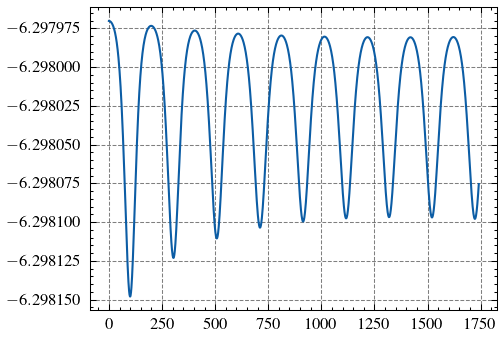

In [91]:
energy_sech_A_2 = w_sech_A_2.get_energy()
plt.plot(energy_sech_A_2[energy_sech_A_2!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


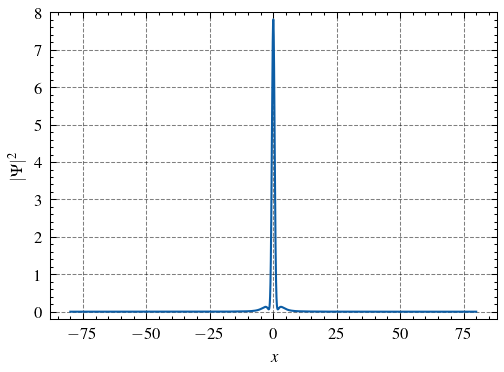

MovieWriter ffmpeg unavailable; using Pillow instead.


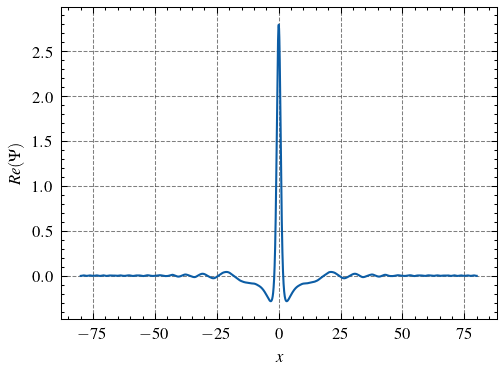

MovieWriter ffmpeg unavailable; using Pillow instead.


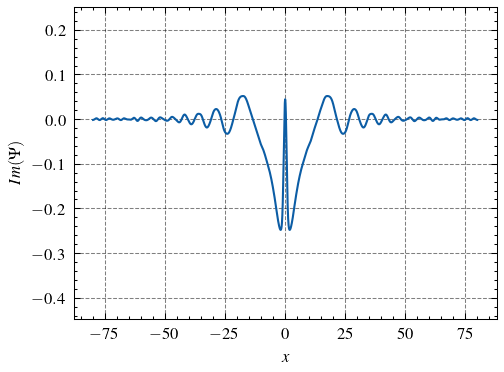

In [93]:
path = "Sech_init/A_2/"
w_sech_A_2.animate_solution(path+"sech_init.gif", 20)
w_sech_A_2.animate_solution(path+"sech_init_real.gif", 20, coord="real")
w_sech_A_2.animate_solution(path+"sech_init_imag.gif", 20, coord="imag")

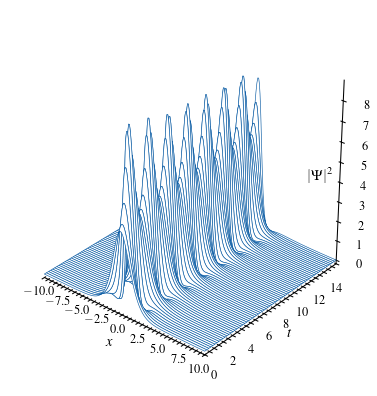

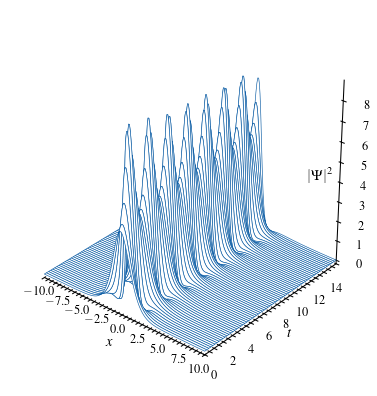

In [94]:
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"sech_init_A_{A}.pdf".format(A=A_sech)
name_pgf = path+"sech_init_A_{A}.pgf".format(A=A_sech)

line_plot_3D(w_sech_A_2.w, w_sech_A_2.x, w_sech_A_2.t, name_pdf, labels, L=10, tf=15, Nt_plot=70, x_rot=-50, z_pad=-27)
line_plot_3D(w_sech_A_2.w, w_sech_A_2.x, w_sech_A_2.t, name_pgf, labels, L=10, tf=15, Nt_plot=70, x_rot=-50, z_pad=-27)

## $A = 3$

In [95]:
tf = 20
Nt = 2000
L = 80
N = 40_000 #15_001

A_sech = 3
sech_init_A_3 = lambda x: sech_init(x, A_sech)

w_sech_A_3 = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sech_A_3.set_init_condition(sech_init_A_3)
w_sech_A_3.solve(b_tol=1e-5)

Iteration  1  of  2000 . Error:  3.1071886392795685e-13 . Newton iterations:  10
Iteration  2  of  2000 . Error:  4.3640596789878814e-13 . Newton iterations:  10
Iteration  3  of  2000 . Error:  7.75160940098175e-13 . Newton iterations:  10
Iteration  4  of  2000 . Error:  9.322919352841818e-14 . Newton iterations:  11
Iteration  5  of  2000 . Error:  2.1429971542453034e-13 . Newton iterations:  11
Iteration  6  of  2000 . Error:  4.831289603599227e-13 . Newton iterations:  11
Iteration  7  of  2000 . Error:  7.670748810672799e-14 . Newton iterations:  12
Iteration  8  of  2000 . Error:  1.7240097060881383e-13 . Newton iterations:  12
Iteration  9  of  2000 . Error:  4.386987710106828e-13 . Newton iterations:  12
Iteration  10  of  2000 . Error:  1.3303585987932015e-13 . Newton iterations:  13
Iteration  11  of  2000 . Error:  4.571360595783668e-13 . Newton iterations:  13
Iteration  12  of  2000 . Error:  1.829648236571304e-13 . Newton iterations:  14
Iteration  13  of  2000 . Error: 

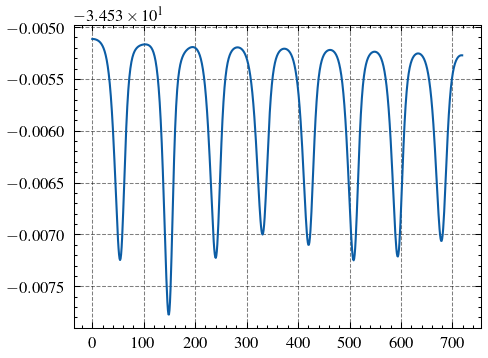

In [96]:
energy_sech_A_3 = w_sech_A_3.get_energy()
plt.plot(energy_sech_A_3[energy_sech_A_3!=0])

MovieWriter ffmpeg unavailable; using Pillow instead.


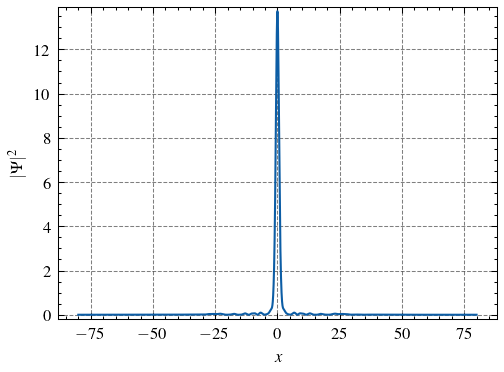

MovieWriter ffmpeg unavailable; using Pillow instead.


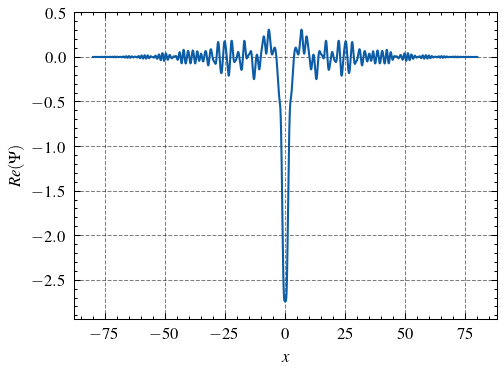

MovieWriter ffmpeg unavailable; using Pillow instead.


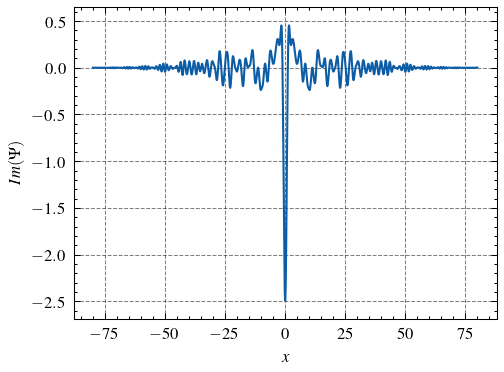

In [97]:
path = "Sech_init/A_3/"
w_sech_A_3.animate_solution(path+"sech_init.gif", 20)
w_sech_A_3.animate_solution(path+"sech_init_real.gif", 20, coord="real")
w_sech_A_3.animate_solution(path+"sech_init_imag.gif", 20, coord="imag")

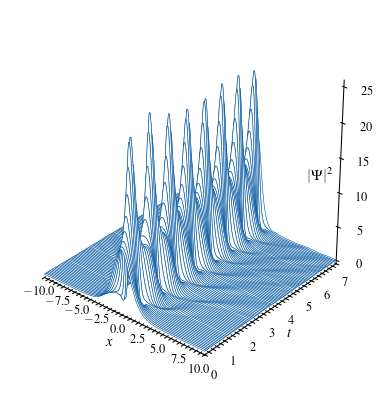

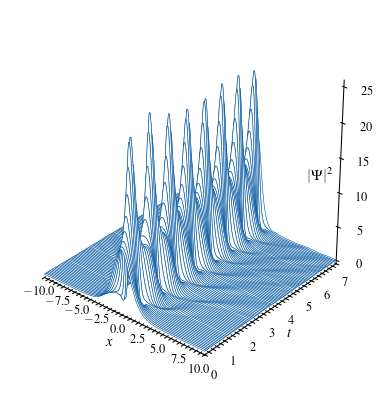

In [102]:
labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path+"sech_init_A_{A}.pdf".format(A=A_sech)
name_pgf = path+"sech_init_A_{A}.pgf".format(A=A_sech)

line_plot_3D(w_sech_A_3.w, w_sech_A_3.x, w_sech_A_3.t, name_pdf, labels, L=10, tf=7, Nt_plot=100, x_rot=-50, z_pad=-27)
line_plot_3D(w_sech_A_3.w, w_sech_A_3.x, w_sech_A_3.t, name_pgf, labels, L=10, tf=7, Nt_plot=100, x_rot=-50, z_pad=-27)